# Prepare an image for painting a beamstop mask
Choose one detector image and run all cells. The saved grayscale PNG has the original pixel dimensions and the same orientation as the MCP analysis plots.

Open the PNG in Paint, paint the beamstop **red**, and save it as `beamstop_mask.png` without resizing. In `mcp_detector_analysis.ipynb`, set `mask_path` to that file.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import h5py
from PIL import Image

def load_detector_image(path, dataset_path=None):
    """Load MCP text, SEXTANTS NeXus, or a detector TIFF image."""
    if path.suffix.lower() == ".txt":
        return np.loadtxt(path)
    if path.suffix.lower() in (".tif", ".tiff"):
        with Image.open(path) as file:
            return np.asarray(file, dtype=float)

    with h5py.File(path, "r") as file:
        if dataset_path is None:
            # SEXTANTS channel numbers change: identify image channels by metadata.
            candidates = []
            for entry in file.values():
                if isinstance(entry, h5py.Group) and "scan_data" in entry:
                    for dataset in entry["scan_data"].values():
                        if isinstance(dataset, h5py.Dataset) and dataset.ndim >= 2:
                            description = str(dataset.attrs.get("interpretation", "")) + str(dataset.attrs.get("long_name", ""))
                            if "image" in description.lower():
                                candidates.append(dataset)
            dataset = max(candidates, key=lambda d: np.prod(d.shape[-2:]))
        else:
            dataset = file[dataset_path]
        print(path.name, "→", dataset.name, dataset.shape)
        image = np.asarray(dataset[()], dtype=float)
    # Multiple exposures in a scan are averaged before combining scans.
    return image.reshape((-1, *image.shape[-2:])).mean(axis=0)


In [2]:
input_folder = Path("raw/MCP")
output_folder = Path("output/mcp_analysis")
image_name = "26-06-09_00267_TDC_2D_chopper_Zone06.txt"
output_path = output_folder / "paint_template_single.png"

# For SEXTANTS CCD/CMOS, use a NeXus filename and the beamtime folder:
# input_folder = Path("../COMET_20260902_Cocoons_Laser_raw")
# image_name = "scanx_0426.nxs"
dataset_path = None              # auto-detect or enter the detector dataset path

# Manual color limits, shared by the preview and saved PNG.
mi = 0.0
ma = 13.0

In [3]:
image = load_detector_image(input_folder / image_name, dataset_path)
print("Image shape:", image.shape)

Image shape: (2000, 2400)


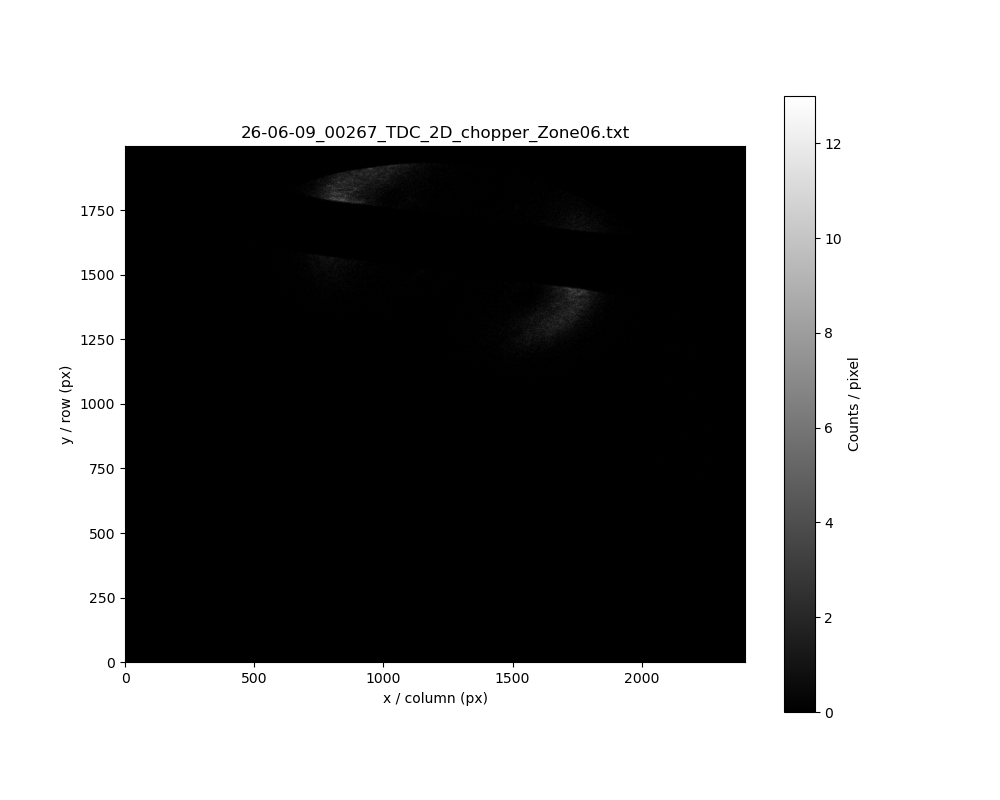

In [4]:
# Show the image in the same orientation and grayscale as the saved PNG.
fig, ax = plt.subplots(figsize=(10, 8))
shown = ax.imshow(image, cmap="gray", origin="lower", vmin=mi, vmax=ma)
ax.set(title=image_name, xlabel="x / column (px)", ylabel="y / row (px)")
fig.colorbar(shown, ax=ax, label="Counts / pixel")
plt.show()

In [5]:
# Save pixels directly: no axes, borders, labels, or resizing.
# Grayscale avoids red pixels before you paint the mask.
output_folder.mkdir(parents=True, exist_ok=True)
plt.imsave(output_path, image, cmap="gray", origin="lower",
           vmin=mi, vmax=ma)
print("Saved:", output_path.resolve())

Saved: /Users/riccardo/Github/SEXTANTS_261105/output/mcp_analysis/paint_template_single.png
